In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

#alkuperäinen kuva
alkuperainen = Image.open(
    "/home/jankkuaho/Pictures/Screenshots/pizza.jpeg"
).convert("RGB")

#harmaasävyinen 8 × 8 -kuva
kuva_pil = alkuperainen.convert("L").resize(
    (8, 8), Image.Resampling.LANCZOS
)
kuva = np.array(kuva_pil, dtype=float)

#DFT ja käänteismuunnos
F = np.fft.fft2(kuva)
spektri = np.log1p(np.abs(np.fft.fftshift(F)))
palautettu = np.fft.ifft2(F).real

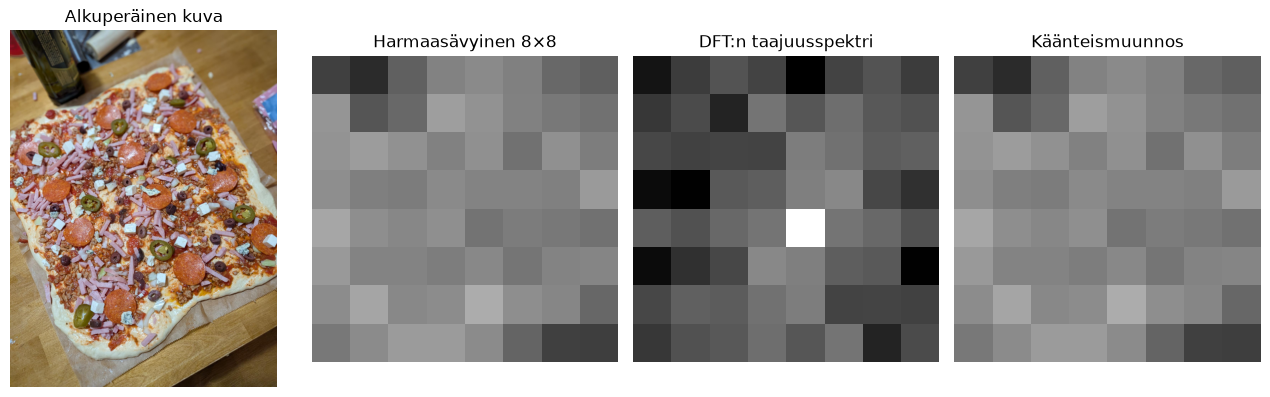

In [ ]:
#vaiheet rinnakkain
fig, akselit = plt.subplots(1, 4, figsize=(13, 4))

akselit[0].imshow(alkuperainen)
akselit[0].set_title("Alkuperäinen kuva")

akselit[1].imshow(
    kuva, cmap="gray", vmin=0, vmax=255, interpolation="nearest"
)
akselit[1].set_title("Harmaasävyinen 8×8")

akselit[2].imshow(spektri, cmap="gray", interpolation="nearest")
akselit[2].set_title("DFT:n taajuusspektri")

akselit[3].imshow(
    palautettu, cmap="gray", vmin=0, vmax=255, interpolation="nearest"
)
akselit[3].set_title("Käänteismuunnos")

for ax in akselit:
    ax.axis("off")

plt.tight_layout()
plt.show()